# Initial Model Attempt with the observed dominant features

## Observations of the most statistical significant features:
    * nonexclbreastfed_adm -> three-order ordinal -> Done. 
    * badhealthduration -> turn it to nominal data -> Done.


    * exclbreastfed - either turn it nominal or re-categorize
    * totalbreastfed - either turn it nominal or re-categorize
    * tobacco -> turn it into nominal data or turn it into 3 categories


    * oxygenavail
    * bcsmotor
    * bcsverbal
    * bednet_adm
    * feedingstatus
    * diarrhoea*
    * bcgscar
    * bcseye
    * respdistress
    * spo2onoxy
    * sympthons_adm_15
    * sympthons_adm_3
    * waterpure
    * weight
    * lactage_mmolpl

    * admitabx_adm_8 -> find other features that correlate with this one.

In [2]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from helper_functions import imputer
from helper_functions.feature_transformer import *
from helper_functions.visualizations import *

data = pd.read_csv("../../preliminar_phase_submision/training_data/SyntheticData_Training.csv")
dictionary = pd.read_csv("tmp_datasets/DataDictionary.csv")
target = "inhospital_mortality"

In [3]:
multi_imputer = imputer.CustomIterativeImputer()
X = data.drop(columns=['inhospital_mortality', 'studyid_adm', 'lengthadm'],
               errors='ignore')
y = data["inhospital_mortality"]
multi_imputer.fit(X)
df = multi_imputer.transform(X)
df[target] = data[target]

In [4]:
transformer = FeatureTransformer()
X, y = df.drop(columns=[target]), df[target]
transformer.fit(X)
X_transformed = transformer.transform(X)
X_transformed.head()

,agecalc_adm,height_cm_adm,weight_kg_adm,muac_mm_adm,hr_bpm_adm,rr_brpm_app_adm,sysbp_mmhg_adm,diasbp_mmhg_adm,temp_c_adm,spo2site1_pc_oxi_adm,...,lightfuel_adm_Other,lightfuel_adm_Other (specify):,lightfuel_adm_Solar lantern,lightfuel_adm_Solar powered bulbs,lightfuel_adm_Tadooba,badhealthduration_adm_1 week - 1 month,badhealthduration_adm_< 1 week,badhealthduration_adm_> 1 year,badhealthduration_adm_In good health prior to this illness,badhealthduration_adm_Unknown
0,0.673338,0.632429,0.512887,1.492372,0.299546,-0.760001,-0.670314,-0.515764,1.010533,0.517016,...,False,False,False,True,False,False,False,False,True,False
1,0.367104,0.829668,1.593994,1.115364,0.065687,-1.098416,0.577809,0.396115,-0.780378,0.517016,...,False,False,False,False,True,False,False,False,True,False
2,0.642715,0.426224,0.512887,0.738355,1.546797,-0.218537,0.661017,1.034429,-0.382398,-3.183328,...,False,False,False,False,False,False,False,False,True,False
3,0.145084,0.381397,0.116481,0.110007,-0.051243,0.187561,-2.251269,-1.245266,0.712048,-1.735368,...,False,False,False,False,True,False,False,False,True,False
4,-0.153495,-0.066874,-0.207851,0.235677,1.079078,1.405854,0.244976,0.578490,-0.780378,0.356131,...,False,False,False,False,True,False,False,False,True,False


In [5]:
selected_cols = [ 'admitabx_adm___8', 'bcsmotor_adm', 'bcsverbal_adm',
 'bednet_adm', 'feedingstatus_adm', 'diarrheaoften_adm',
 'bcgscar_adm', 'bcseye_adm', 'lactate_mmolpl_adm', 
 'respdistress_adm', 'spo2onoxy_adm', 'symptoms_adm___15', 
 'symptoms_adm___3', 'waterpure_adm', 'weight_kg_adm',
 'exclbreastfed_adm', 'totalbreastfed_adm', 'tobacco_adm']

In [6]:
train_cols, hot_encoded_cols = [], []
for col in selected_cols:
    if col in X_transformed.columns.tolist():
        train_cols.append(col)
    else:
        hot_encoded_cols.append(col)
hot_encoded_cols = tuple(hot_encoded_cols)
for col in X_transformed.columns.tolist():
    if col.startswith(hot_encoded_cols):
        train_cols.append(col)
train_cols

['admitabx_adm___8',
 'bcsmotor_adm',
 'bcsverbal_adm',
 'bednet_adm',
 'feedingstatus_adm',
 'diarrheaoften_adm',
 'bcgscar_adm',
 'bcseye_adm',
 'lactate_mmolpl_adm',
 'respdistress_adm',
 'spo2onoxy_adm',
 'symptoms_adm___15',
 'symptoms_adm___3',
 'waterpure_adm',
 'weight_kg_adm',
 'exclbreastfed_adm_2 months',
 'exclbreastfed_adm_3 months',
 'exclbreastfed_adm_4 months',
 'exclbreastfed_adm_5 months',
 'exclbreastfed_adm_6 months',
 'exclbreastfed_adm_More than 6 months',
 'exclbreastfed_adm_Unknown',
 'exclbreastfed_adm_never exclusively breastfed',
 'totalbreastfed_adm_4-6 months',
 'totalbreastfed_adm_7-12 months',
 'totalbreastfed_adm_>12 months',
 'totalbreastfed_adm_Unknown',
 'tobacco_adm_Less than monthly',
 'tobacco_adm_Monthly',
 'tobacco_adm_Never',
 'tobacco_adm_Weekly']

In [79]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, recall_score

def train_model(columns=train_cols):

    X = X_transformed.copy()[columns]

    # Train-test split
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)


    # Logistic Regression model with class weight balancing
    model = LogisticRegression(class_weight='balanced', solver='liblinear')
    model.fit(X_train, y_train)

    # Predictions
    y_pred = model.predict(X_test)

    # Evaluation
    recall = recall_score(y_test, y_pred, pos_label=1)

    report = classification_report(y_test, y_pred, output_dict=True)
    recall_class_1 = report['1']['recall']
    f1_class_1 = report['1']['f1-score']


    # Feature importance analysis
    feature_importance = pd.DataFrame({'Feature': X.columns,
                                    'Coefficient': model.coef_[0]})
    feature_importance = feature_importance.sort_values(by='Coefficient', ascending=False)
    return recall_class_1, f1_class_1

train_model()

(0.5, 0.21428571428571427)

In [54]:
selected_columns

array(['totalbreastfed_adm_4-6 months', 'symptoms_adm___15',
       'bcgscar_adm', 'bcsverbal_adm', 'exclbreastfed_adm_5 months',
       'exclbreastfed_adm_never exclusively breastfed',
       'tobacco_adm_Weekly', 'exclbreastfed_adm_6 months',
       'spo2onoxy_adm', 'bcseye_adm', 'totalbreastfed_adm_Unknown',
       'waterpure_adm', 'tobacco_adm_Monthly', 'bcsmotor_adm',
       'exclbreastfed_adm_3 months', 'admitabx_adm___8',
       'feedingstatus_adm', 'weight_kg_adm', 'bednet_adm'], dtype=object)

Recall (Class 1): 0.3333
              precision    recall  f1-score   support

           0       0.97      0.85      0.90       412
           1       0.09      0.33      0.14        18

    accuracy                           0.83       430
   macro avg       0.53      0.59      0.52       430
weighted avg       0.93      0.83      0.87       430

Recall (Class 1): 0.3333
              precision    recall  f1-score   support

           0       0.97      0.85      0.90       412
           1       0.09      0.33      0.14        18

    accuracy                           0.83       430
   macro avg       0.53      0.59      0.52       430
weighted avg       0.93      0.83      0.87       430

Recall (Class 1): 0.3333
              precision    recall  f1-score   support

           0       0.97      0.85      0.90       412
           1       0.09      0.33      0.14        18

    accuracy                           0.83       430
   macro avg       0.53      0.59      0.52       430

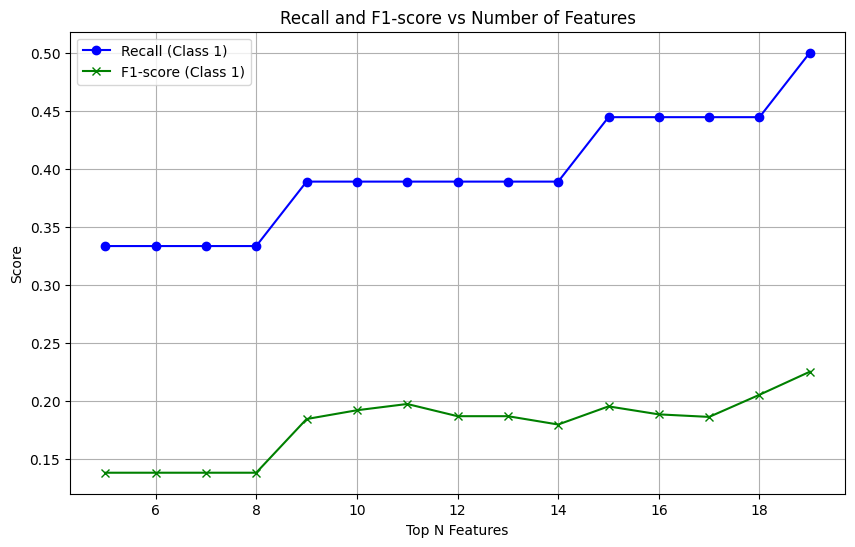

In [53]:
n_vs_score = {}

for top_n in range(5, 20):
    selected_columns = feature_importance.sort_values(by='Abs_Coefficient', ascending=False).head(top_n).Feature.values
    recall, f1 = train_model(selected_columns)
    n_vs_score[top_n] = [recall, f1]

# graph to plot the recall and f1 versus top_n
import pandas as pd
score_df = pd.DataFrame(n_vs_score).T
score_df.columns = ['Recall', 'F1-score']

# Plot recall and F1-score versus top_n
plt.figure(figsize=(10, 6))
plt.plot(score_df.index, score_df['Recall'], label='Recall (Class 1)', marker='o', color='blue')
plt.plot(score_df.index, score_df['F1-score'], label='F1-score (Class 1)', marker='x', color='green')

# Add labels and title
plt.xlabel('Top N Features')
plt.ylabel('Score')
plt.title('Recall and F1-score vs Number of Features')
plt.legend()
plt.grid(True)

# Show the plot
plt.show()   



In [100]:
train_model(['totalbreastfed_adm_4-6 months', 'tobacco_adm_Monthly', 
            #  'exclbreastfed_adm_5 months',
            'bcseye_adm', 
             'bcsverbal_adm', 'bcsmotor_adm', 'symptoms_adm___15', 
            #  'bcgscar_adm', 
             'spo2onoxy_adm', 'agecalc_adm']
)

(0.7222222222222222, 0.2708333333333333)

In [57]:
feature_importance.sort_values(by='Abs_Coefficient', ascending=False)

,Feature,Coefficient,Abs_Coefficient
23,totalbreastfed_adm_4-6 months,1.805206,1.805206
11,symptoms_adm___15,1.383994,1.383994
6,bcgscar_adm,-1.303407,1.303407
2,bcsverbal_adm,1.280717,1.280717
18,exclbreastfed_adm_5 months,-1.111774,1.111774
22,exclbreastfed_adm_never exclusively breastfed,-1.109097,1.109097
30,tobacco_adm_Weekly,-1.024465,1.024465
19,exclbreastfed_adm_6 months,-0.938263,0.938263
10,spo2onoxy_adm,-0.809751,0.809751
7,bcseye_adm,-0.787108,0.787108


  0%|          | 0/7 [00:00<?, ?it/s]

Processing 6-feature sets:   0%|          | 0/38760 [00:00<?, ?it/s]

Processing 7-feature sets:   0%|          | 0/77520 [00:00<?, ?it/s]

Processing 8-feature sets:   0%|          | 0/125970 [00:00<?, ?it/s]

Processing 9-feature sets:   0%|          | 0/167960 [00:00<?, ?it/s]

Processing 10-feature sets:   0%|          | 0/184756 [00:00<?, ?it/s]

Processing 11-feature sets:   0%|          | 0/167960 [00:00<?, ?it/s]

Processing 12-feature sets:   0%|          | 0/125970 [00:00<?, ?it/s]

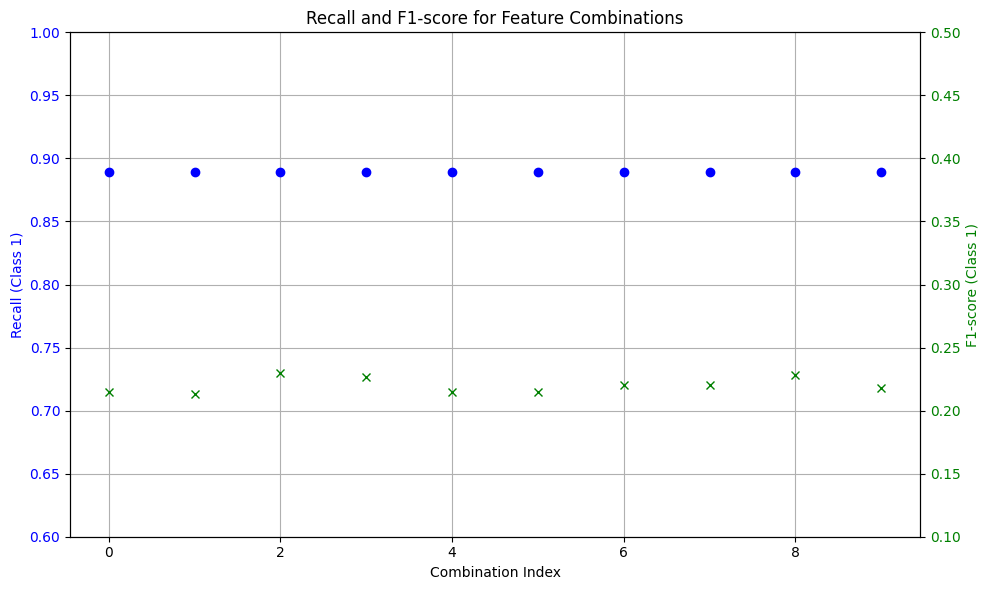

In [104]:
import itertools
import pandas as pd
import matplotlib.pyplot as plt
import math
from tqdm.notebook import tqdm  # Use tqdm.notebook for Jupyter

# Select top 20 features based on absolute coefficient values
N = 20
top_N_features = feature_importance.sort_values(by='Abs_Coefficient', ascending=False).head(N).Feature.values

# Dictionary to store results
n_vs_score = {}

# Loop over different feature set sizes (6 to 12)
for k in tqdm(range(6, 13)):
    combinations = list(itertools.combinations(top_N_features, k))
    num_combinations = math.comb(N, k)

    for combination in tqdm(combinations, total=num_combinations, desc=f"Processing {k}-feature sets"):
        recall, f1 = train_model(list(combination) + ['agecalc_adm'])
        n_vs_score[combination] = [recall, f1]

# Convert results to DataFrame
score_df = pd.DataFrame.from_dict(n_vs_score, orient='index', columns=['Recall', 'F1-score'])
score_df_sorted = score_df.sort_values(by='Recall', ascending=False)

# Plot recall and F1-score vs the combinations (first 10 for clarity)
fig, ax1 = plt.subplots(figsize=(10, 6))
ax1.plot(range(10), score_df_sorted['Recall'][:10], 'o', color='blue', label='Recall (Class 1)')
ax1.set_xlabel('Combination Index')
ax1.set_ylabel('Recall (Class 1)', color='blue')
ax1.set_ylim(0.6, 1.0)
ax1.tick_params(axis='y', labelcolor='blue')

ax2 = ax1.twinx()
ax2.plot(range(10), score_df_sorted['F1-score'][:10], 'x', color='green', label='F1-score (Class 1)')
ax2.set_ylabel('F1-score (Class 1)', color='green')
ax2.set_ylim(0.1, 0.5)
ax2.tick_params(axis='y', labelcolor='green')

plt.title('Recall and F1-score for Feature Combinations')
ax1.grid(True)
plt.tight_layout()
plt.show()


  0%|          | 0/7 [00:00<?, ?it/s]

Processing 6-feature sets:   0%|          | 0/38760 [00:00<?, ?it/s]

Processing 7-feature sets:   0%|          | 0/77520 [00:00<?, ?it/s]

Processing 8-feature sets:   0%|          | 0/125970 [00:00<?, ?it/s]

Processing 9-feature sets:   0%|          | 0/167960 [00:00<?, ?it/s]

Processing 10-feature sets:   0%|          | 0/184756 [00:00<?, ?it/s]

Processing 11-feature sets:   0%|          | 0/167960 [00:00<?, ?it/s]

Processing 12-feature sets:   0%|          | 0/125970 [00:00<?, ?it/s]

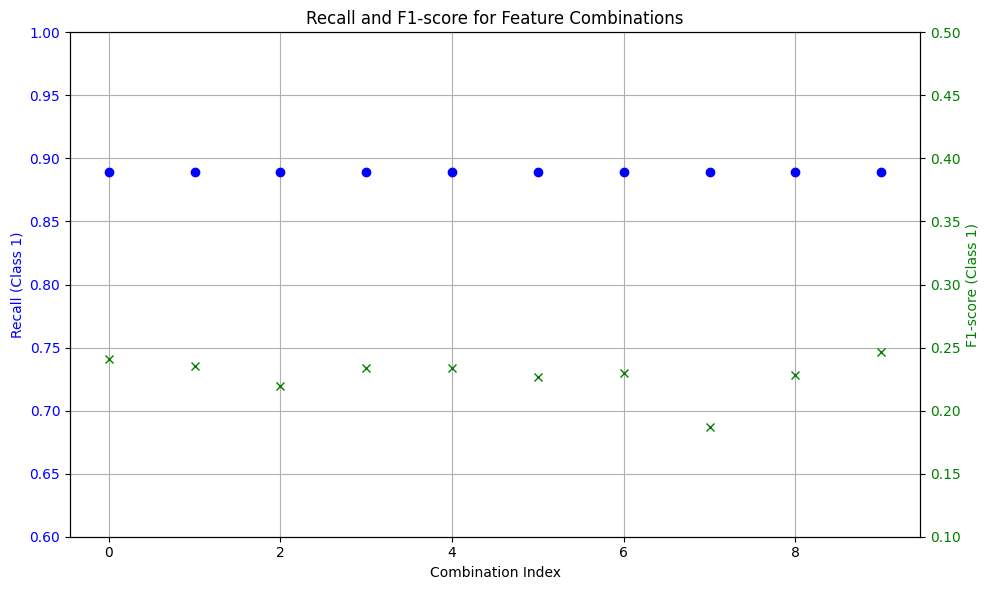

In [105]:
import itertools
import pandas as pd
import matplotlib.pyplot as plt
import math
from tqdm.notebook import tqdm  # Use tqdm.notebook for Jupyter

# Select top 20 features based on absolute coefficient values
N = 20
top_N_features = feature_importance.sort_values(by='Abs_Coefficient', ascending=False).head(N).Feature.values

# Dictionary to store results
n_vs_score = {}

# Loop over different feature set sizes (6 to 12)
for k in tqdm(range(6, 13)):
    combinations = list(itertools.combinations(top_N_features, k))
    num_combinations = math.comb(N, k)

    for combination in tqdm(combinations, total=num_combinations, desc=f"Processing {k}-feature sets"):
        recall, f1 = train_model(list(combination))
        n_vs_score[combination] = [recall, f1]

# Convert results to DataFrame
score_df = pd.DataFrame.from_dict(n_vs_score, orient='index', columns=['Recall', 'F1-score'])
score_df_sorted = score_df.sort_values(by='Recall', ascending=False)

# Plot recall and F1-score vs the combinations (first 10 for clarity)
fig, ax1 = plt.subplots(figsize=(10, 6))
ax1.plot(range(10), score_df_sorted['Recall'][:10], 'o', color='blue', label='Recall (Class 1)')
ax1.set_xlabel('Combination Index')
ax1.set_ylabel('Recall (Class 1)', color='blue')
ax1.set_ylim(0.6, 1.0)
ax1.tick_params(axis='y', labelcolor='blue')

ax2 = ax1.twinx()
ax2.plot(range(10), score_df_sorted['F1-score'][:10], 'x', color='green', label='F1-score (Class 1)')
ax2.set_ylabel('F1-score (Class 1)', color='green')
ax2.set_ylim(0.1, 0.5)
ax2.tick_params(axis='y', labelcolor='green')

plt.title('Recall and F1-score for Feature Combinations')
ax1.grid(True)
plt.tight_layout()
plt.show()


In [107]:
score_df_sorted[:5]

,Recall,F1-score
"(totalbreastfed_adm_4-6 months, exclbreastfed_adm_never exclusively breastfed, spo2onoxy_adm, totalbreastfed_adm_Unknown, tobacco_adm_Monthly, admitabx_adm___8, feedingstatus_adm, weight_kg_adm, bednet_adm, totalbreastfed_adm_>12 months)",0.888889,0.240602
"(symptoms_adm___15, exclbreastfed_adm_5 months, spo2onoxy_adm, tobacco_adm_Monthly, exclbreastfed_adm_3 months, feedingstatus_adm, weight_kg_adm, bednet_adm)",0.888889,0.235294
"(symptoms_adm___15, bcgscar_adm, exclbreastfed_adm_never exclusively breastfed, tobacco_adm_Weekly, spo2onoxy_adm, waterpure_adm, tobacco_adm_Monthly, admitabx_adm___8, feedingstatus_adm, weight_kg_adm, bednet_adm)",0.888889,0.219178
"(symptoms_adm___15, bcgscar_adm, tobacco_adm_Weekly, exclbreastfed_adm_6 months, spo2onoxy_adm, tobacco_adm_Monthly, feedingstatus_adm, weight_kg_adm, bednet_adm, totalbreastfed_adm_>12 months)",0.888889,0.233577
"(symptoms_adm___15, bcgscar_adm, exclbreastfed_adm_never exclusively breastfed, tobacco_adm_Weekly, spo2onoxy_adm, waterpure_adm, tobacco_adm_Monthly, exclbreastfed_adm_3 months, feedingstatus_adm, weight_kg_adm, bednet_adm)",0.888889,0.233577


In [108]:
score_df_sorted.sort_values(by="F1-score", ascending=False)[:5]

,Recall,F1-score
"(tobacco_adm_Weekly, spo2onoxy_adm, bcseye_adm, totalbreastfed_adm_Unknown, waterpure_adm, admitabx_adm___8)",0.555556,0.344828
"(spo2onoxy_adm, bcseye_adm, totalbreastfed_adm_Unknown, waterpure_adm, tobacco_adm_Monthly, admitabx_adm___8)",0.555556,0.344828
"(tobacco_adm_Weekly, spo2onoxy_adm, bcseye_adm, waterpure_adm, tobacco_adm_Monthly, admitabx_adm___8)",0.555556,0.344828
"(tobacco_adm_Weekly, spo2onoxy_adm, bcseye_adm, totalbreastfed_adm_Unknown, waterpure_adm, tobacco_adm_Monthly, admitabx_adm___8)",0.555556,0.344828
"(exclbreastfed_adm_5 months, exclbreastfed_adm_never exclusively breastfed, spo2onoxy_adm, bcseye_adm, totalbreastfed_adm_Unknown, admitabx_adm___8, weight_kg_adm)",0.777778,0.337349
